<h1>Unsupervised Learning: K-Means Clustering

How K-Means Works (The Simple Analogy)

Imagine you have a big pile of mixed-up t-shirts and you want to group them into 3 sizes (Small, Medium, Large), but none of them have labels.
    
Pick the centers (Centroids): You randomly pick 3 t-shirts from the pile to represent your initial "center points" for Small, Medium, and Large.
    
Assign the shirts: You look at every other shirt in the pile and place it next to whichever of those 3 initial shirts it matches closest in size.
    
Update the centers: For each of your 3 new piles, you look at all the shirts in it and find the absolute average size. This average shirt becomes the new "center point."

Repeat: You repeat steps 2 and 3. You shuffle the shirts again based on the new averages. You keep doing this until the shirts stop moving between piles.Python Implementation



Think about it like this

Suppose we have:

● ● ●              ▲ ▲ ▲
● ●                 ▲ ▲

          ■ ■
          ■ ■

and we choose:

K = 3

K-Means tries to create:

Cluster 1 → ● ● ● ● ●
Cluster 2 → ▲ ▲ ▲ ▲ ▲
Cluster 3 → ■ ■ ■ ■

It wants the points within each cluster to be close together.

So conceptually:

Good clustering

→ points within each cluster are close

→ clusters are relatively distinct

<h3>This is the fun part.


Suppose:

K = 3
Step 1 — Pick 3 initial centroids

Think of them as temporary cluster centers:

      ●

              ●

   ●

Step 2 — Assign each observation to the nearest centroid

Point → nearest center

Step 3 — Move each centroid

After assigning the points, calculate a new center for each group.

Step 4 — Repeat

Assign points
     ↓

Move centroids
     ↓

Assign points again
     ↓

Move centroids again
     ↓
...

Eventually the clusters stabilize.

That's essentially K-Means.

<h2>Let's test it out

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [4]:
np.random.seed(42)

cluster_1 = np.random.randn(50, 2) + [2, 2]
cluster_2 = np.random.randn(50, 2) + [8, 8]
cluster_3 = np.random.randn(50, 2) + [2, 8]

X = np.vstack([cluster_1, cluster_2, cluster_3])

In [5]:
#We created 150 obsevations with 2 features

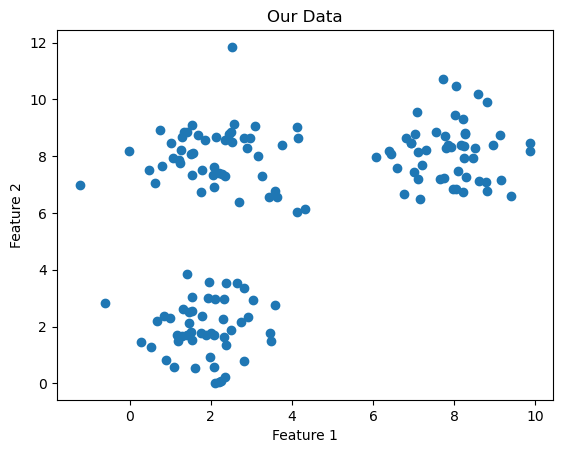

In [6]:
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Our Data")
plt.show()

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X)

C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3, n_init=10, random_state=42)

In [6]:
#Now let's see what it did
labels = kmeans.labels_

print(labels)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


These nnumbers are cluster ID's. Thy dont' mean 

0 = good

1 = moderate

2 = poor

K_Means doesn't know what they mean, it just labels them

In [8]:
#To see the centers
print(kmeans.cluster_centers_)

[[7.90454712 8.14006205]
 [1.86432437 1.9279826 ]
 [2.12894675 8.00084575]]


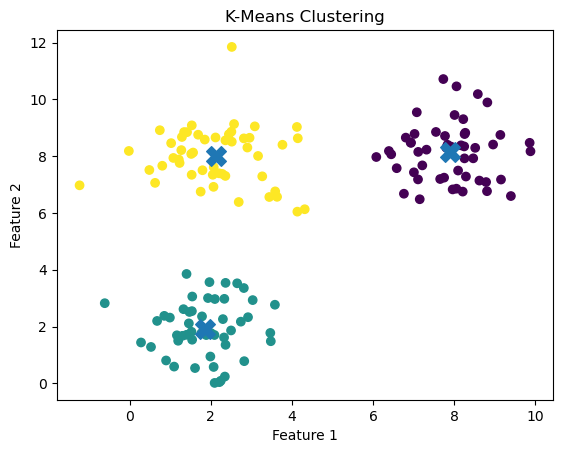

In [9]:
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.show()

<h3>Because K-Means is distance based, it needs scaling as well

<h3>How do we know whether K = 3 is reasonable?

Elbow Method

Looks at inertia as K changes.

Silhouette Score

Measures how well observations fit within their own cluster compared with other clusters.

In [1]:
#Using the dataset we just created, run k = 2,3,4


In [7]:
kmeans1 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
kmeans1.fit(X)

C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3, n_init=10, random_state=42)

In [8]:
kmeans2 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
kmeans2.fit(X)

C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3, n_init=10, random_state=42)

In [9]:
kmeans3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
kmeans3.fit(X)

C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3, n_init=10, random_state=42)

In [11]:
print(kmeans1.inertia_)

print(kmeans2.inertia_)
print(kmeans3.inertia_)

286.1842142470733
286.1842142470733
286.1842142470733


Remember inertia_

You just saw:

kmeans.inertia_

Inertia measures, roughly:

How close the observations are to the centroids of their assigned clusters.

Lower inertia means the points are closer to their cluster centers.

So naturally:

More clusters
      ↓
More specific groups
      ↓
Lower inertia

For example, you might get:

K = 1 → 500
K = 2 → 280
K = 3 → 150
K = 4 → 120
K = 5 → 105
K = 6 → 98

Notice what's happening:

1 → 2   huge improvement
2 → 3   huge improvement
3 → 4   smaller improvement
4 → 5   small improvement
5 → 6   very small improvement

The point where the improvement starts becoming much smaller is the elbow.

2. Why is it called an elbow?




There is a noticeable bend around:

K = 3

That's the "elbow."

The intuition is:

After K = 3, adding more clusters doesn't improve compactness nearly as much.

In [12]:
#Let's look at the elbow by checking the inertias from k = 2 - 10
inertias = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    inertias.append(kmeans.inertia_)

print(inertias)

C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to 

[1114.273196995296, 286.1842142470733, 253.73240126205653, 212.88988732808792, 180.30806895909706, 153.024159208912, 132.6134039317056, 115.71231871059908, 104.6357197645437]


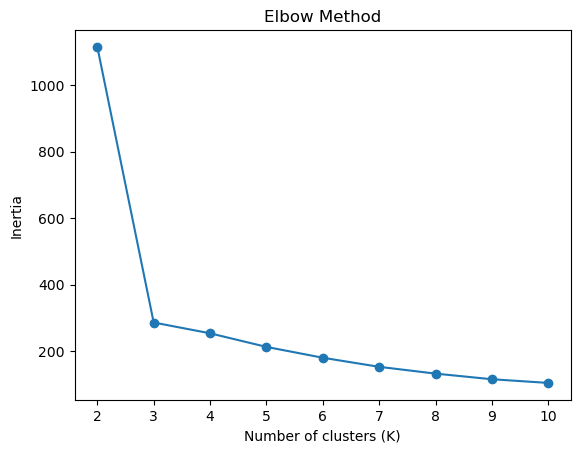

In [13]:
#Let's plot it
plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

We have an elbow at k = 3

<h3>Silhouette Score

Silhouette score asks roughly:

"Is each point closer to its own cluster than to the other clusters?"

It ranges roughly from:

-1 → poor clustering

 0 → overlapping / unclear
 
+1 → very well-separated clusters

Higher is generally better.

In [15]:
#Using the same range, let's calculate silhouette score
from sklearn.metrics import silhouette_score
scores = []

for k in range(2, 11):
        kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
        )
        kmeans.fit(X)
#For each KMean, calculate the s score
        scores.append(silhouette_score(X, kmeans.labels_ ))

print(scores)

C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to 

[np.float64(0.5630079420728803), np.float64(0.6966245199215827), np.float64(0.5610165394666676), np.float64(0.4553202535789546), np.float64(0.32524332542997986), np.float64(0.3526795066048582), np.float64(0.36752897190377143), np.float64(0.3844417735349387), np.float64(0.39454385511689366)]


C:\Users\HP\miniconda3\envs\fyp\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


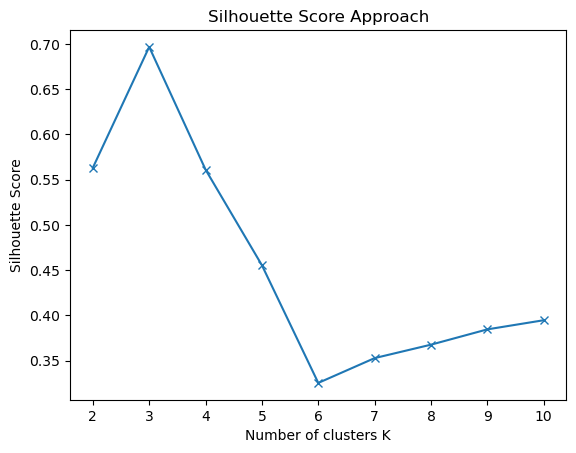

In [16]:
#plot it
plt.plot(range(2, 11), scores, marker = "x")
plt.xlabel("Number of clusters K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Approach")
plt.show()

And now you understand an important limitation of K-Means

K-Means doesn't know:

"This cluster is a rural area."

It only knows:

"These points are numerically similar."

So after clustering, domain interpretation comes afterward.

This distinction becomes very important when using clustering in research.